## Setup

**Notebook produces RMSE vs Leadtime**


In [1]:
import os, sys

# Make the ecCodes DLL findable (must run BEFORE importing xarray/cfgrib)
os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]

import xarray as xr
import cfgrib
import snotelpy as sp
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from datetime import datetime
import pandas as pd
from ens import load_forecast, forecast_basin, observed_gain, score_members

### Config

In [36]:

# La Nina event matches test file currently 
events = pd.DataFrame([
    {"phase": "La Nina",  "winter": "2021-22", "target_start": "2022-01-10", "target_end": "2022-01-17"},
    {"phase": "El Nino",  "winter": "2016-17", "target_start": "2016-03-21", "target_end": "2016-03-28"},  # placeholder
    {"phase": "Neutral",  "winter": "XXXX-XX", "target_start": "XXXX-XX-XX", "target_end": "XXXX-XX-XX"},  # placeholder
])

EVENT = 1 # 0 for la nina, 1 for el nino, 2 for neutral

# Lead times (weeks before the start of the target window)
LEAD_WEEKS = [1, 2, 3, 4]


# ECMWF S2S init weekdays (Mon=0, Thu=3). VERIFY against the current S2S docs.
INIT_WEEKDAYS = [0, 3]

#snotel
#SNOTEL_STATIONS = ["842:CO:SNTL"]     # swap for a list of basin stations later HUC = 

HUC = 	14010003 #eagle


SNOTEL_ELEMENT  = ['WTEQ']
START_DATE ='2021-12-10'
END_DATE ='2022-01-20'

SNOTEL_CACHE    = "NINO_snotel_obs_eagle_basin.nc"     # fetch once, then load from disk


# Forecast
FORECAST_VAR   = "sf"                 # snowfall water equivalent, accumulated, kg m-2
MM_PER_INCH    = 25.4                 # 1 kg m-2 = 1 mm water
GRIB_DIR       = "."                  # where the .grib files live




START_DATE='2021-12-16' #snotel date range
END_DATE='2022-01-31'




## Observations (snotel)

#### Pull Your data only do this once

In [38]:
stations = sp.get_stations(station_triplets=[':CO:SNTL'],elements=SNOTEL_ELEMENT,hucs=HUC,returnType='gpd',)


SNOTEL_STATIONS = stations['stationTriplet'].tolist()
# SNOTEL_STATIONS.remove('1326:CO:SNTL')

print(SNOTEL_STATIONS)
ds = sp.fetch_snotel(stations=SNOTEL_STATIONS, elements=SNOTEL_ELEMENT, duration="DAILY",start_date='2016-03-10',end_date='2016-03-30',include_coords=True)



sp.save_data(ds, 'NINO_snotel_obs_eagle_basin')



['1041:CO:SNTL', '1040:CO:SNTL', '842:CO:SNTL']


#### Load CACHE/data from last step

In [39]:
observations_raw = xr.open_dataset(SNOTEL_CACHE)

observations_raw


print(min(observations_raw['longitude']).values)

print(max(observations_raw['longitude']).values)

-106.544
-106.38019


Get Snotels Basin Coords

In [40]:



obs_lat = [float(min(observations_raw['latitude'].values)), float(max(observations_raw['latitude'].values) )]
obs_lon = [float((min(observations_raw['longitude'].values ) % 360)), float((max(observations_raw['longitude'].values)) % 360)]
print(obs_lat)
print(obs_lon)

 


[39.59871, 39.61765]
[253.45600000000002, 253.61981]


## Combine Basin into 1 series

In [41]:
basin_obs = observations_raw.mean(dim= "station")

basin_obs

<xarray.Dataset> Size: 336B
Dimensions:  (time: 21)
Coordinates:
  * time     (time) datetime64[ns] 168B 2016-03-10 2016-03-11 ... 2016-03-30
Data variables:
    WTEQ     (time) float64 168B 11.87 11.87 11.9 11.97 ... 14.93 15.1 15.5
Attributes:
    source:    USDA NRCS AWDB REST API
    network:   SNOTEL
    duration:  DAILY

## Forecast loading

In [6]:
sf_raw = load_forecast(r"DATA\s2s_20160222.grib")

c:\Users\tatev\miniforge3\envs\atoc-2025-lite\Lib\site-packages\cfgrib\xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)
c:\Users\tatev\miniforge3\envs\atoc-2025-lite\Lib\site-packages\cfgrib\xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs

### Bound the forecast by snotel basin coords

In [8]:
                   
basin_fc = forecast_basin(ds = sf_raw,target_end=events.target_end[EVENT], target_start=events.target_start[EVENT],station_lats=obs_lat, station_lons=obs_lon)
basin_fc

<xarray.DataArray 'sf' (number: 50)> Size: 400B
array([0.2416473 , 0.30113972, 0.42359305, 1.51827953, 0.73025365,
       0.41088819, 0.9059092 , 0.07355362, 0.55935547, 0.20547389,
       0.80934884, 1.14476065, 0.59694657, 0.74289947, 0.02899655,
       0.49465528, 0.54661564, 0.27219301, 0.13776567, 1.32714293,
       0.06801106, 0.42942484, 1.13413623, 0.82641149, 0.37080139,
       1.04177786, 0.71300574, 0.47921115, 0.43139172, 0.79253584,
       0.21436654, 0.5524711 , 0.57331435, 1.09519362, 0.74756192,
       0.33749779, 0.78929943, 0.48997686, 0.26661612, 0.20284136,
       0.72971612, 0.19601237, 0.6126394 , 0.40191839, 1.24292578,
       0.27844562, 1.62684537, 0.63691374, 0.19980839, 0.03506841])
Coordinates:
  * number   (number) int32 200B 1 2 3 4 5 6 7 8 9 ... 43 44 45 46 47 48 49 50
    time     datetime64[ns] 8B 2016-02-22
    surface  float64 8B 0.0
Attributes: (12/31)
    GRIB_paramId:                             228144
    GRIB_dataType:                            pf
    GRIB_numberOfPoints:                      30
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_shortName:                           sf
    GRIB_totalNumber:                         51
    GRIB_units:                               kg m**-2
    long_name:                                Snowfall water equivalent
    units:                                    kg m**-2
    standard_name:                            unknown

In [49]:

obs_gain  = observed_gain(snotel= observations_raw,target_start= events.target_start[EVENT], target_end= events.target_end[EVENT])
print(float(obs_gain))

1.4999999999999993


In [50]:
score_members(members=basin_fc,obs =  obs_gain)

Ensemble mean Error: -0.9175656942321507
Rank of Obs: 0.96
STD: 0.38148389273140926


### Plotting

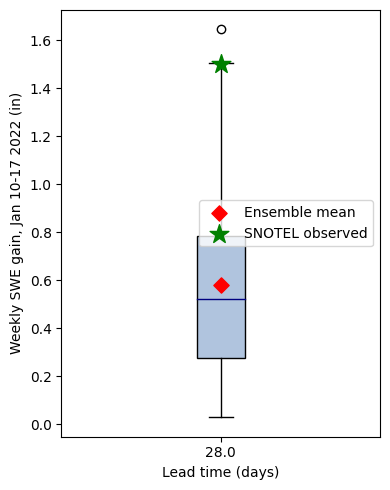

In [51]:
fig, ax = plt.subplots(figsize=(4, 5))

lead_wk =  ((np.datetime64(events.target_start[EVENT]) - sf_raw.time.values) / np.timedelta64(1, 'D')) 

ax.boxplot(basin_fc.values, positions=[lead_wk], widths=0.3,
           showfliers=True, patch_artist=True,
           boxprops=dict(facecolor="lightsteelblue"),
           medianprops=dict(color="navy"))

ax.scatter(lead_wk, float(basin_fc.mean()), color="red", marker="D", s=60, zorder=3, label="Ensemble mean")
ax.scatter(lead_wk, obs_gain, color="green", marker="*", s=200, zorder=3, label="SNOTEL observed")

ax.set_xlim(lead_wk - 1, lead_wk + 1)
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Weekly SWE gain, Jan 10-17 2022 (in)")
ax.legend()
plt.tight_layout()
plt.show()



Run it for all of lead times

First load all datasets for phase:
- This will be faster after first time

In [12]:
#EL nino, forecasting during march 23 2016 storm
week4_fc = load_forecast(r'DATA\s2s_20160222.grib')
week3_fc = load_forecast(r'DATA\s2s_20160229.grib')
week2_fc = load_forecast(r'DATA\s2s_20160307.grib')
week1_fc = load_forecast(r'DATA\s2s_20160314.grib')


march_nino_fc = [week1_fc,week2_fc,week3_fc,week4_fc]



c:\Users\tatev\miniforge3\envs\atoc-2025-lite\Lib\site-packages\cfgrib\xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)
c:\Users\tatev\miniforge3\envs\atoc-2025-lite\Lib\site-packages\cfgrib\xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs

In [42]:
#load snotel data, change in config
observations_raw = xr.open_dataset(SNOTEL_CACHE)





#get observations bounding box
obs_lat = [float(min(observations_raw['latitude'].values )), float(max(observations_raw['latitude'].values) )]
obs_lon = [float((min(observations_raw['longitude'].values ) % 360)), float((max(observations_raw['longitude'].values) ) % 360)]
print(obs_lat)
print(obs_lon)

#veiw snotel to make sure it looks ok 
observations_raw


[39.59871, 39.61765]
[253.45600000000002, 253.61981]


<xarray.Dataset> Size: 888B
Dimensions:    (time: 21, station: 3)
Coordinates:
  * time       (time) datetime64[ns] 168B 2016-03-10 2016-03-11 ... 2016-03-30
  * station    (station) <U12 144B '1041:CO:SNTL' '1040:CO:SNTL' '842:CO:SNTL'
    latitude   (station) float64 24B 39.6 39.6 39.62
    longitude  (station) float64 24B -106.5 -106.5 -106.4
    elevation  (station) float64 24B ...
Data variables:
    WTEQ       (time, station) float64 504B ...
Attributes:
    source:    USDA NRCS AWDB REST API
    network:   SNOTEL
    duration:  DAILY

In [43]:
basin_forecasts = {}

for i,ds in enumerate(march_nino_fc):
    basin_forecasts[f"basin_fc_{i+1}"] = forecast_basin(ds=ds,
                          target_start=events.target_start[EVENT],
                          target_end=events.target_end[EVENT],
                          station_lats=observations_raw.latitude.values,
                          station_lons=observations_raw.longitude.values)
    
    
    basin_forecasts[f"basin_fc_{i+1}"].attrs["lead_days"] = ((np.datetime64(events.target_start[EVENT]) - ds.time.values) / np.timedelta64(1, 'D')) #add how many lead days to each dataset 
    
    
print(basin_forecasts['basin_fc_4'])

<xarray.DataArray 'sf' (number: 50)> Size: 400B
array([0.30221705, 0.31160075, 0.43603657, 1.5444038 , 0.78983615,
       0.49201019, 0.90997782, 0.09834551, 0.46823954, 0.24754959,
       0.99301336, 1.17852524, 0.63089297, 0.76938058, 0.03705003,
       0.57492618, 0.56239146, 0.29983437, 0.16527786, 1.32933703,
       0.05418854, 0.51313008, 1.28034443, 0.94975379, 0.37215345,
       1.06310838, 0.7967344 , 0.44320147, 0.52780907, 0.94557198,
       0.25465357, 0.59556475, 0.68950365, 1.18684573, 0.89085914,
       0.36878013, 0.82153004, 0.56822028, 0.27833888, 0.20654401,
       0.77557143, 0.17777849, 0.69636202, 0.45522158, 1.35738818,
       0.32687745, 1.25981691, 0.60256551, 0.21065238, 0.0448101 ])
Coordinates:
  * number   (number) int32 200B 1 2 3 4 5 6 7 8 9 ... 43 44 45 46 47 48 49 50
    time     datetime64[ns] 8B 2016-02-22
    surface  float64 8B 0.0
Attributes: (12/32)
    GRIB_paramId:                             228144
    GRIB_dataType:                            

In [44]:
print(min(basin_forecasts['basin_fc_2']).values)
print(max(basin_forecasts['basin_fc_2']).values)

fc = basin_forecasts['basin_fc_1']
print(float(fc.mean()), float(fc.median()))
print(float((fc > obs_gain).mean()))      # fraction of members above the observation
print(np.percentile(fc, [10, 25, 75, 90]))
print(np.allclose(basin_forecasts['basin_fc_1'], basin_forecasts['basin_fc_4']))

for i, d in enumerate(march_nino_fc):
    print(i, d.time.values, float(d['sf'].isel(step=-1, number=0, latitude=0, longitude=0)))

-0.00025084492898342535
1.1631905992363747
0.4206722740220451 0.41188445327286727
0.0
[0.13619893 0.22526198 0.55316883 0.75226415]
False
0 2016-03-14T00:00:00.000000000 19.8984375
1 2016-03-07T00:00:00.000000000 23.84375
2 2016-02-29T00:00:00.000000000 27.7265625
3 2016-02-22T00:00:00.000000000 9.5234375


In [45]:
#Snotel observations


obs_gain = observed_gain(snotel=observations_raw,
            target_start=events.target_start[EVENT],
            target_end=events.target_end[EVENT])
print(obs_gain)

<xarray.DataArray 'WTEQ' ()> Size: 8B
array(1.5)
Attributes:
    description:  Depth of water that would theoretically result if the entir...
    name:         SNOW WATER EQUIVALENT
    units:        in


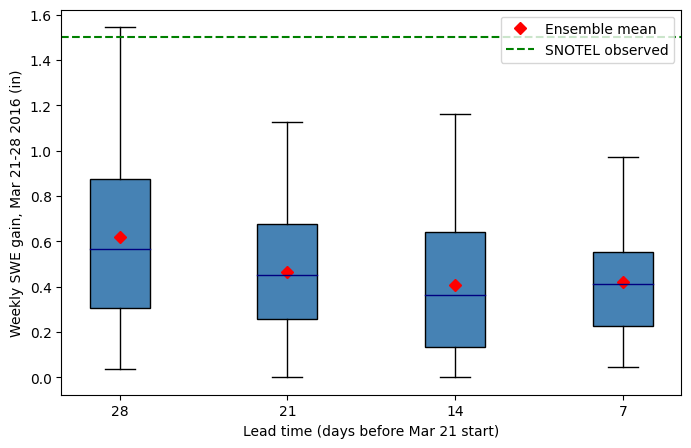

In [65]:
fig, ax = plt.subplots(figsize = (8,5))

data = [basin_forecasts['basin_fc_4'], basin_forecasts['basin_fc_3'], basin_forecasts['basin_fc_2'], basin_forecasts['basin_fc_1']]
leads = [28,21,14,7]

ax.boxplot(data,positions=leads,widths=2.5,patch_artist=True,
           boxprops=dict(facecolor = "steelblue"),
           medianprops = dict(color = "navy"))
ax.plot(leads, [d.mean() for d in data], "D", color="red", label="Ensemble mean")
ax.axhline(obs_gain, color="green", ls="--", label="SNOTEL observed")

ax.set_xticks(leads)
ax.invert_xaxis()                        # time runs toward the event on the right
ax.set_xlabel("Lead time (days before Mar 21 start)")
ax.set_ylabel("Weekly SWE gain, Mar 21-28 2016 (in)")
ax.legend()


Calculate RMSE per Lead

In [66]:
rows = []
for lead, members in zip(leads, data):        # members: 50 values in inches
    err = members - obs_gain
    rows.append({
        "lead_days": lead,
        "rmse": np.sqrt(np.mean(err**2)),     # square, mean over members, root
        "mean_err": members.mean() - obs_gain, # signed bias of ensemble mean
        "abs_mean_err": abs(members.mean() - obs_gain),
        "spread": members.std(),
    })
df = pd.DataFrame(rows).sort_values("lead_days")

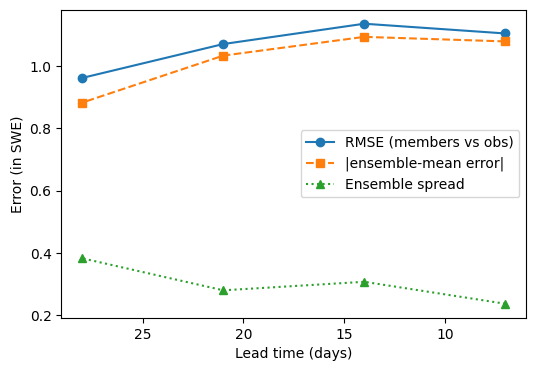

In [67]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(df.lead_days, df.rmse, "o-", label="RMSE (members vs obs)")
ax.plot(df.lead_days, df.abs_mean_err, "s--", label="|ensemble-mean error|")
ax.plot(df.lead_days, df.spread, "^:", label="Ensemble spread")
ax.invert_xaxis()
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Error (in SWE)")
ax.legend()

Text(0.5, 1.0, 'March 21 - 28th 2016 Snow Event')

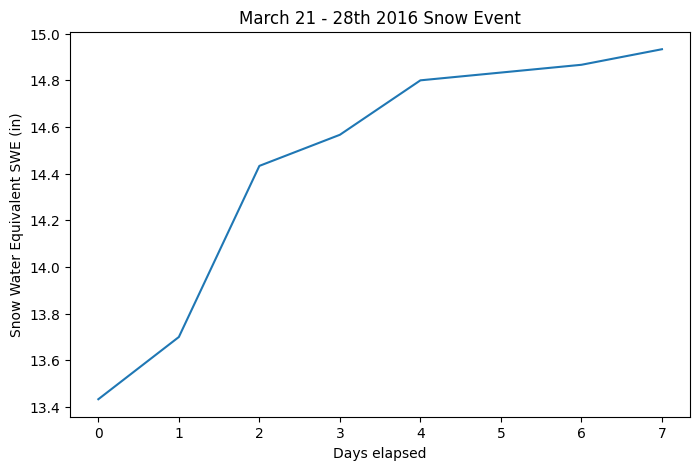

In [92]:

SWE_data = basin_obs['WTEQ'].sel(time = slice('2016-03-21','2016-03-28'))

fig, ax = plt.subplots(figsize = (8,5))

ax.plot(SWE_data)
ax.set_xlabel('Days elapsed')
ax.set_ylabel('Snow Water Equivalent SWE (in)')
ax.set_title('March 21 - 28th 2016 Snow Event')
